# Step 3: Look at the data (EDA)
*Same as `src/03_eda.py`; charts are shown here instead of saved.*

**In short** (what this notebook shows)

- **What:** Exploratory analysis: engagement by language (ANOVA), expert vs novice, correlation of voice and face features with engagement, PCA plot.
- **Needs the NoXi data?** Yes (the feature table).
- **Result / use:** Experts 0.65 and novices 0.50 engagement; voice features correlate more strongly (0.38) than face (0.16).

### Dataset
**NoXi** (NOvice eXpert Interaction) - multimodal recordings of expert-novice conversations with continuous engagement labels.
- Dataset page (MultiMediate): https://multimediate.perceptualui.org/datasets/Dataset_NoXi/ (if it is offline, use the links below)
- Paper: A. Cafaro et al., "The NoXi Database: Multimodal Recordings of Mediated Novice-Expert Interactions", ACM ICMI 2017: https://eprints.nottingham.ac.uk/45827 (DOI https://doi.org/10.1145/3136755.3136780)
- Extension NoXi+J (2024): https://arxiv.org/abs/2409.13726
- Data access: University of Augsburg, Human-Centered AI lab - noxi@hcai.eu
- Used here: **24 conversations** (English 026, 027, 028, 029, 030, 058, 062, 063; French 001, 007, 009, 011, 013, 014, 020, 021; German 068, 070, 072, 073, 074, 075, 076, 077) from the NoXi train set:
  eGeMAPS voice features, OpenFace 2.0 face features, engagement labels (25 per second) and the pretrained-Transformer embeddings shipped with the corpus.
- Licence: NoXi is available for research under an End-User Licence Agreement (signed by the supervisor). The data is **not included** here and must not be shared;
  request access on the dataset page and place the downloaded zips as described in `01_extract_data`.

Go to the project folder.

In [2]:
import os
if os.getcwd().endswith("notebooks"):
    os.chdir("..")          # work from the project folder

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

df = pd.read_parquet("data/features/noxi_engagement.parquet")
feature_cols = []
for c in df.columns:
    if c.startswith("voice_") or c.startswith("face_"):
        feature_cols.append(c)
print("windows:", len(df))

windows: 48486


**How much data per language**, and **average engagement per language**.

In [4]:
print(df["language"].value_counts())
print(df.groupby("language")["engagement"].mean())

language
French     19060
English    15074
German     14352
Name: count, dtype: int64
language
English    0.541176
French     0.600584
German     0.578426
Name: engagement, dtype: float64


**ANOVA:** is the average engagement different between the languages? (p < 0.05 = yes)

In [5]:
english = df[df["language"] == "English"]["engagement"]
french = df[df["language"] == "French"]["engagement"]
german = df[df["language"] == "German"]["engagement"]
f_value, p_value = stats.f_oneway(english, french, german)
print("F =", round(f_value, 2), " p =", p_value)

F = 697.96  p = 1.4556842769273064e-299


**Charts:** distribution, by language, by role.

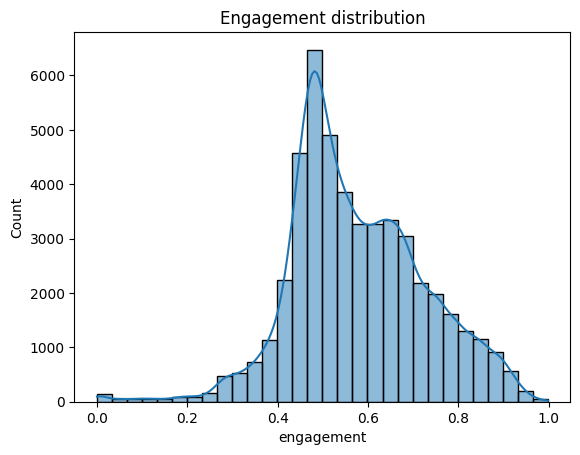

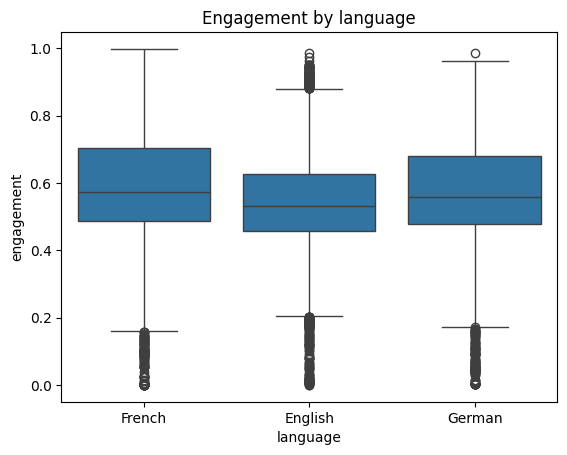

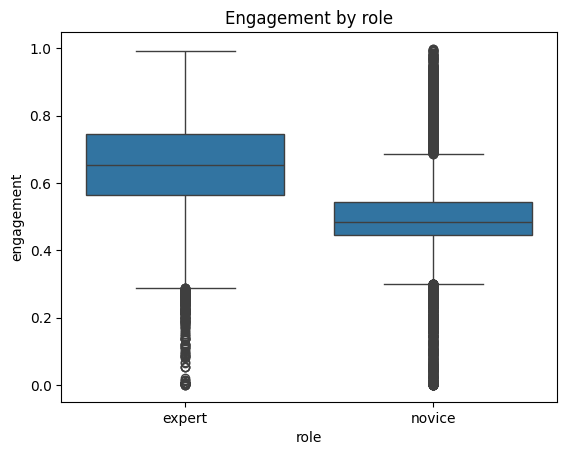

role
expert    0.653237
novice    0.497875
Name: engagement, dtype: float64


In [6]:
sns.histplot(df["engagement"], bins=30, kde=True)
plt.title("Engagement distribution")
plt.show()

sns.boxplot(data=df, x="language", y="engagement")
plt.title("Engagement by language")
plt.show()

sns.boxplot(data=df, x="role", y="engagement")
plt.title("Engagement by role")
plt.show()
print(df.groupby("role")["engagement"].mean())

**Which features go with engagement?** Correlation of every feature with engagement.

C:\Users\SHUBHAM KUMAR\Downloads\cross-lingual-nonverbal\.venv\Lib\site-packages\numpy\lib\function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\SHUBHAM KUMAR\Downloads\cross-lingual-nonverbal\.venv\Lib\site-packages\numpy\lib\function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


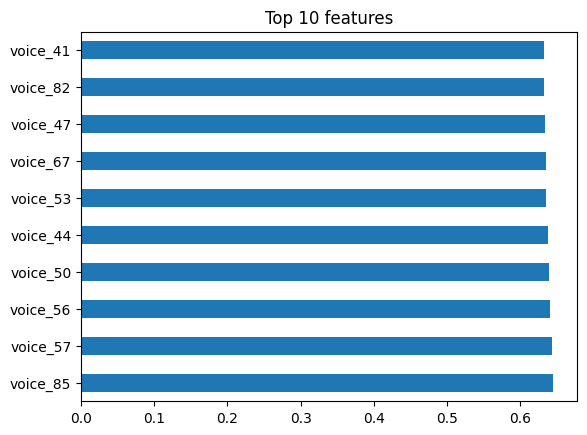

In [7]:
corr = df[feature_cols].corrwith(df["engagement"]).abs()
corr = corr.sort_values(ascending=False)
corr.head(10).plot(kind="barh")
plt.title("Top 10 features")
plt.show()

**Voice vs face:** average correlation of each group.

In [8]:
voice_cols = []
face_cols = []
for c in feature_cols:
    if c.startswith("voice_"):
        voice_cols.append(c)
    else:
        face_cols.append(c)
print("voice:", round(corr[voice_cols].mean(), 3))
print("face: ", round(corr[face_cols].mean(), 3))

voice: 0.381
face:  0.162


**PCA:** squeeze all features into 2 numbers and colour each window by language.

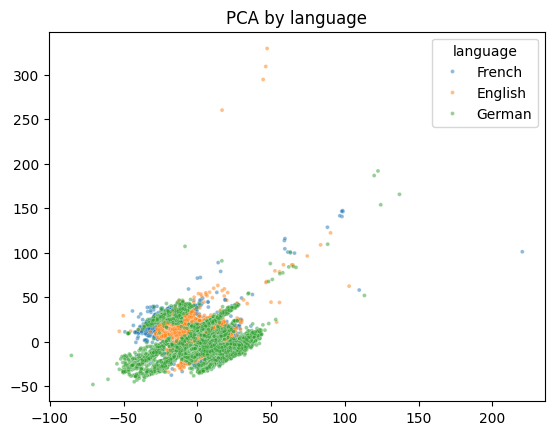

In [9]:
X = StandardScaler().fit_transform(df[feature_cols].fillna(0))
points = PCA(n_components=2).fit_transform(X)
sns.scatterplot(x=points[:, 0], y=points[:, 1], hue=df["language"], s=8, alpha=0.5)
plt.title("PCA by language")
plt.show()